***

# Trabajo Biofísica: Clasificiación y Correlación de las estadísticas en Pokémon

*** 

# Velasco García, Lucía
# Villaverde Turnes, David

***
## Introducción

Pokémon es una saga de videojuegos creada y desarrollada por *Gamefreak* en 1996, que se popularizó rápidamente debido a su estilo sencillo de juego y prograsión. Esta consiste en combates entre unas criaturas llamadas pokémon, que se asemejan a distintos animales, y que puedes mejorar combatiendo contra otras criaturas (entrenando). 

Estas criaturas están agrupadas en algo que llamamos *tipos*, que vendría a representar de alguna manera el elemento que los caracteriza. Estos van desde cosas más habituales como fuego, agua o electricidad, a cosas más hetéreas, como fantasma, dragón, etc. A mayores de esto, cada pokémon se caracteriza por tener unas determinadas estadísticas, que vendrían a ser cuán fuertes son. Estas estadísticas son los puntos de salud, ataque y defensa, ataque y defensa especiales, y velocidad. 

Estas estadísticas, en principio, no tienen por qué estar relacionadas con los tipos. Sin embargo, siempre se ha dicho en particular de los tipos psíquico y lucha que son contrarios en estadísticas: los tipo lucha se caracterizan por tener alto ataque y defensa (que vendrían a representar los golpes 'de contacto') y bajo ataque y defensa especial (lo que serían ataques 'a distancia'). Mientras que en el tipo psíquico ocurre justo lo contrario.

Nuestro objetivo en este trabajo será, en primer lugar, analizar la relación que puede haber entre las estadísticas de ataque y ataque especial de todos los pokémon, y después quedarnos solo con los que tengan o tipo lucha o tipo psíquico para entrenar un modelo y ver si es capaz o no a partir de sus estadísticas si sabe decir si son (o no) de un tipo u otro.

Como último ejercicio, vamos a basarnos en otro tipo de clasificación entre todos los pokémon: si son o no legendarios. En los juegos, se viene a decir que los pokémon legendarios o singulares se caracterizan por tener una fuerza y unas características extraordinarias. Vamos a comprobar si esto es verídico o no entrenando un modelo de red neuronal que analice todas las estadísticas de cada pokémon, y que sea capaz de predecir si el pokémon es legendario o no.

***

Base de datos: https://www.kaggle.com/datasets/abcsds/pokemon?resource=download

***

***

## Pasos previos

Vamos a, en primer lugar, cargar nuestra base de datos y echar un vistazo a que hay: las distintas categorías que encontramos, si hay o no valores duplicados o perdidos, etc. etc.

***

In [3]:
#hola david, espero que estés viendo esto. aquí voy a hacer las cosas del trabajo.

#hola Luve, soy megaretrasado


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datos

#Directorio de Luve (Cuando lo vayas a usar Lucía, descomenta el tuyo y comenta el mío)

#df = pd.read_csv(r'C:\Users\PC\4º\Biofísica\trabajobio\trabajobio\archive\Pokemon.csv')

#Directorio de David

df = pd.read_csv(r'C:\Users\david\OneDrive - Universidade de Santiago de Compostela\4º Curso\Biofísica\Primer trabajo (ahora sí)\trabajobio\archive\Pokemon.csv')

# Información general
print('\n','=' * 50)
print(f"Total de Pokémon: {df.shape[0]}")
print(f"Total de variables: {df.shape[1]}")
print('\n','=' * 50)

print('\n','=' * 50)
print("\nColumnas del dataset:")
print(df.columns.tolist())
print('\n','=' * 50)

print('\n','=' * 50)
print("\nNúmero de Pokémon de cada tipo:")
print(df[['Type 1','Type 2']].stack().value_counts())
print('\n','=' * 50)

print('\n','=' * 50)
print(f'\n Número de Pokémon legendarios: {df["Legendary"].sum()}')
print(f'\n Número de Pokémon no legendarios: {df.shape[0] - df["Legendary"].sum()}')
print('\n','=' * 50)
# Mostramos las primeras filas
display(df.head())




Total de Pokémon: 800
Total de variables: 13



Columnas del dataset:
['#', 'Name', 'Type 1', 'Type 2', 'Total', 'HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed', 'Generation', 'Legendary']



Número de Pokémon de cada tipo:
Water       126
Normal      102
Flying      101
Grass        95
Psychic      90
Bug          72
Ground       67
Fire         64
Poison       62
Rock         58
Fighting     53
Dark         51
Dragon       50
Electric     50
Steel        49
Ghost        46
Fairy        40
Ice          38
Name: count, dtype: int64



 Número de Pokémon legendarios: 65

 Número de Pokémon no legendarios: 735



,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


***

## Preparación y limpieza de los datos

Antes de entrenar la red neuronal, es necesario preparar el conjunto de datos para garantizar que la información utilizada sea adecuada.

En esta etapa se comprobarán las dimensiones del dataset, los tipos de variables, la existencia de duplicados y los posibles valores ausentes.


En primer lugar, implementaremos un modelo SVR para detectar si hay cierta correlación entre las parejas de ataque y ataque especial y defensa en general.


Más adelante, seleccionaremos únicamente los Pokémon cuyo tipo principal sea psíquico o lucha. Esta selección permitirá plantear un problema de clasificación binaria mediante una red neuronal artificial.

Por último, volveremos a contar con todos los datos para determinar si es se tratan de legendarios o no.


***

In [4]:
# Dimensiones iniciales

print('\n','=' * 50)
print("Dimensiones iniciales:", df.shape)
print('\n','=' * 50)


# Primeras filas
print('\n','=' * 50)
display(df.head())
print('\n','=' * 50)

# Información de las variables
print('\n','=' * 50)
df.info()
print('\n','=' * 50)

# Eliminación de duplicados
df = df.drop_duplicates()

print('\n','=' * 50)
print("\nDimensiones tras eliminar duplicados:", df.shape)
print('\n','=' * 50)

# Eliminación de valores perdidos
df = df.dropna()


print('\n','=' * 50)
print("\nDimensiones tras eliminar valores perdidos:", df.shape)
print('\n','=' * 50)



Dimensiones iniciales: (800, 13)




,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False




<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   #           800 non-null    int64
 1   Name        800 non-null    str  
 2   Type 1      800 non-null    str  
 3   Type 2      414 non-null    str  
 4   Total       800 non-null    int64
 5   HP          800 non-null    int64
 6   Attack      800 non-null    int64
 7   Defense     800 non-null    int64
 8   Sp. Atk     800 non-null    int64
 9   Sp. Def     800 non-null    int64
 10  Speed       800 non-null    int64
 11  Generation  800 non-null    int64
 12  Legendary   800 non-null    bool 
dtypes: bool(1), int64(9), str(3)
memory usage: 75.9 KB



Dimensiones tras eliminar duplicados: (800, 13)



Dimensiones tras eliminar valores perdidos: (414, 13)



***

Vemos que se pierden algunas filas, es decir, algunos Pokemon. Aproximadamente la mitad. 


Pero vamos a ver ahora que lo que ocurre es que nos está eliminando los que solo tienen un tipo. Comprobémoslo.

***


In [5]:
#Volvemos a cargar el archivo de origen

df = pd.read_csv(r'C:\Users\david\OneDrive - Universidade de Santiago de Compostela\4º Curso\Biofísica\Primer trabajo (ahora sí)\trabajobio\archive\Pokemon.csv')
#df = pd.read_csv(r'C:\Users\PC\4º\Biofísica\trabajobio\trabajobio\archive\Pokemon.csv')

print('\n' + '=' * 50)
print(df['Type 2'].unique())
print('\n' + '=' * 50)

print('\n' + '=' * 50)

restantes = df.shape[0] - df['Type 2'].isna().sum()
print(f"Número de Pokémon sin tipo secundario: {restantes}")

print('\n' + '=' * 50)


<StringArray>
[  'Poison',        nan,   'Flying',   'Dragon',   'Ground',    'Fairy',
    'Grass', 'Fighting',  'Psychic',    'Steel',      'Ice',     'Rock',
     'Dark',    'Water', 'Electric',     'Fire',    'Ghost',      'Bug',
   'Normal']
Length: 19, dtype: str


Número de Pokémon sin tipo secundario: 414





Como vemos, el número de pokemons que nos quedan son justamente  los que quedaban después de eliminar los nans. 


Para poder trabajar más cómodamente con los datos, vamos a sustituir los 'nan' por 'None'.



In [6]:
df['Type 2'] = df['Type 2'].fillna('None')
print('\n' + '=' * 50)
print(df['Type 2'].unique())
print('\n' + '=' * 50)


<StringArray>
[  'Poison',     'None',   'Flying',   'Dragon',   'Ground',    'Fairy',
    'Grass', 'Fighting',  'Psychic',    'Steel',      'Ice',     'Rock',
     'Dark',    'Water', 'Electric',     'Fire',    'Ghost',      'Bug',
   'Normal']
Length: 19, dtype: str



***

# Parte 1: SVR para evaluar las parejas de ataque y defensa físicos y especiales

*** 

Vamos ahora a escoger como variable X en primer lugar el ataque y evaluar la dependencia de Y, el ataque especial. Después, haremos lo propio con las defensas.

***

Vamos a basarnos en el archivo de SVR que podemos encontrar en el aula virtual.

***

In [7]:
#Preparamos en primer lugar los datos

X = df['Attack'].values.reshape(-1, 1)
Y = df['Sp. Atk'].values.reshape(-1, 1)

#Escalamos los datos para que estén entre 0 y 1, ya que el SVR es sensible a la escala de los datos

from sklearn.preprocessing import MinMaxScaler 
X_scaler = MinMaxScaler()
Y_scaler = MinMaxScaler()
X = X_scaler.fit_transform(X) 
Y = Y_scaler.fit_transform(Y)

***

Vamos ahora a dividir los datos en conjuntos de entrenamiento y prueba. Entrenaremos al modelo con los de entrenamiento, y le daremos nuevos datos (los del conjunto de prueba) para comprobar si el modelo funciona o no

***


In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.33, random_state=100)

***
Ahora tenemos que escoger los parámetros del modelo de regresión. Viendo los resultados que obtuvimos en clase, y ya que realmente no sabemos si hay una dependencia o no, ya que solo es un dicho que se tiene entre jugadores, vamos a escoger como kernel el 'rbf', que es el menos restrictivo y el que puede caracterizar más casos. Vamos a escoger como $\gamma$=1, que es valor por defecto, para ser más permisivos con el modelo. Por último, igual que en clase, escogemos C=100

***

Entrenamiento 0.2591379987549308
Prueba 0.2788761849520067


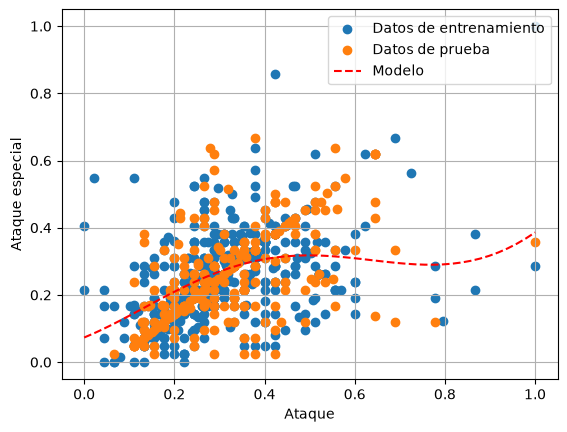

In [18]:
from sklearn.svm import SVR

svr_rbf = SVR(kernel='rbf', C=100, gamma=1, epsilon=.1) 

# Creando el modelo y entrenando
reg = svr_rbf.fit(X_train,Y_train.reshape(-1))

# Prediciendo valores de entrenamiento
Y_train_hat = svr_rbf.predict(X_train)

# Prediciendo valores de validación
Y_test_hat = svr_rbf.predict(X_test)



# Creamos un scatter plot con los datos de entrenamiento y validación
plt.scatter(X_train, Y_train)
plt.scatter(X_test, Y_test)

# En X_plot creamos un continuo de datos entre 0 y 1
X_plot = np.linspace(0,1).reshape(-1, 1)
Y_plot = svr_rbf.predict(X_plot)


# Graficamos el modelo de base radial
plt.plot(X_plot, Y_plot,"r--")
plt.xlabel('Ataque')
plt.ylabel('Ataque especial')
plt.legend(['Datos de entrenamiento', 'Datos de prueba', 'Modelo'])
plt.grid()
# Calculamos el error
from sklearn.metrics import r2_score
print("Entrenamiento", r2_score(Y_train, Y_train_hat))
print("Prueba", r2_score(Y_test, Y_test_hat))

***

Lo que vemos es que el modelo no es nada bueno. La correlación es muy baja. Probando con el modelo lineal da un poco peor. Por lo tanto, vemos que realmente, en general, no depende mucho el ataque especial del ataque que tenga el pokémon. ¿Qué pasa con la defensa?

***


Entrenamiento 0.2591379987549308
Prueba 0.2788761849520067


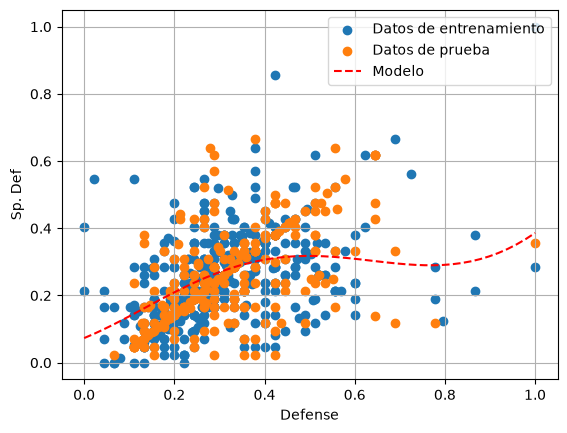

In [20]:
#Hacemos todo exactamente igual pero con las variables de defensa y defensa especial

X = df['Defense'].values.reshape(-1, 1)
Y = df['Sp. Def'].values.reshape(-1, 1)


X_scaler = MinMaxScaler()
Y_scaler = MinMaxScaler()
X = X_scaler.fit_transform(X) 
Y = Y_scaler.fit_transform(Y)

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.33, random_state=100)



svr_rbf = SVR(kernel='rbf', C=100, gamma=1, epsilon=.1) 


reg = svr_rbf.fit(X_train,Y_train.reshape(-1))
Y_train_hat = svr_rbf.predict(X_train)
Y_test_hat = svr_rbf.predict(X_test)
plt.scatter(X_train, Y_train)
plt.scatter(X_test, Y_test)

X_plot = np.linspace(0,1).reshape(-1, 1)
Y_plot = svr_rbf.predict(X_plot)



plt.plot(X_plot, Y_plot,"r--")
plt.xlabel('Defense'); plt.ylabel('Sp. Def')
plt.legend(['Datos de entrenamiento', 'Datos de prueba', 'Modelo'])
plt.grid()

print("Entrenamiento", r2_score(Y_train, Y_train_hat))
print("Prueba", r2_score(Y_test, Y_test_hat))

***

Aunque con la defensa obtenemos un resultado un poco mejor, sigue sin ser la gran cosa. Por tanto, parece que más bien desmentimos el hecho de que haya una relación entre estadísticas en el caso más general. Ahora bien, ¿será entonces cierto que se destinguen el tipo lucha y psíquico?

***

***

# Parte 2: ¿Psíquico o lucha?

## Escogemos las variables que vamos a utilizar

Como dijimos arriba, vamos a intentar predecir el tipo de pokemon en cuestión según sus estadísiticas, restringiéndonos solamente a clasificarlos en si son psíquico o si son lucha. Para ello, nuestra variable X van a ser todas las estadísticas del pokemon, mientras que la Y serán justamente sus tipos, pero quedándonos ya solo con los pokemon tipo psíquico y lucha.

***

In [22]:
# Variables que utilizaremos
estadísticas = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']

# Seleccionamos únicamente Pokémon de tipo Psíquico y Lucha
df_filtrado = df[df['Type 1'].isin(['Psychic', 'Fighting']) | df['Type 2'].isin(['Psychic', 'Fighting'])].copy()


# Creamos la variable objetivo
# 1 = Psychic
# 0 = Fighting

df_filtrado['target'] = ((df_filtrado['Type 1'] == 'Psychic') | (df_filtrado['Type 2'] == 'Psychic')).astype(int)

print('\n' + '=' * 50)

print('\nDistribución de las clases:')

print(df_filtrado[['Type 1','Type 2']].stack().value_counts())
print('\n' + '=' * 50)
print('\n' + '=' * 50)
print("\nNúmero de Pokémon seleccionados:", len(df_filtrado))
print('\n' + '=' * 50)
display(df_filtrado)



Distribución de las clases:
Psychic     90
None        58
Fighting    53
Fire        10
Steel       10
Water        8
Flying       7
Grass        6
Fairy        6
Dark         6
Normal       4
Dragon       4
Rock         3
Ice          2
Bug          2
Ground       2
Poison       2
Ghost        1
Name: count, dtype: int64



Número de Pokémon seleccionados: 137



,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary,target
61,56,Mankey,Fighting,None,305,40,80,35,35,45,70,1,False,0
62,57,Primeape,Fighting,None,455,65,105,60,60,70,95,1,False,0
67,62,Poliwrath,Water,Fighting,510,90,95,95,70,90,70,1,False,0
68,63,Abra,Psychic,None,310,25,20,15,105,55,90,1,False,1
69,64,Kadabra,Psychic,None,400,40,35,30,120,70,105,1,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,686,Inkay,Dark,Psychic,288,53,54,53,37,46,45,6,False,1
757,687,Malamar,Dark,Psychic,482,86,92,88,68,75,73,6,False,1
771,701,Hawlucha,Fighting,Flying,500,78,92,75,74,63,118,6,False,0
797,720,HoopaHoopa Confined,Psychic,Ghost,600,80,110,60,150,130,70,6,True,1


***

Vamos a ver un primer momento cómo se distribuyen las estadísitcas según sea tipo psíquico o lucha. De esta manera, veremos si hay alguna diferencia apreciable entre los tipo lucha y los tipo psíquico.

***

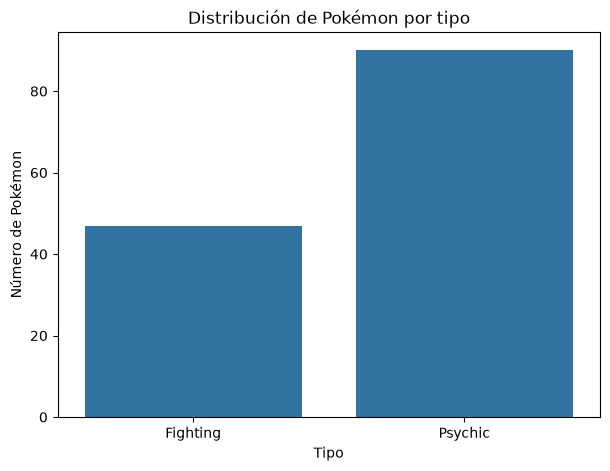

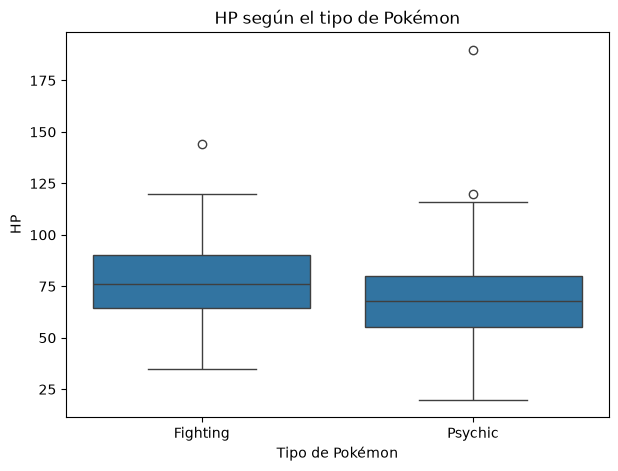

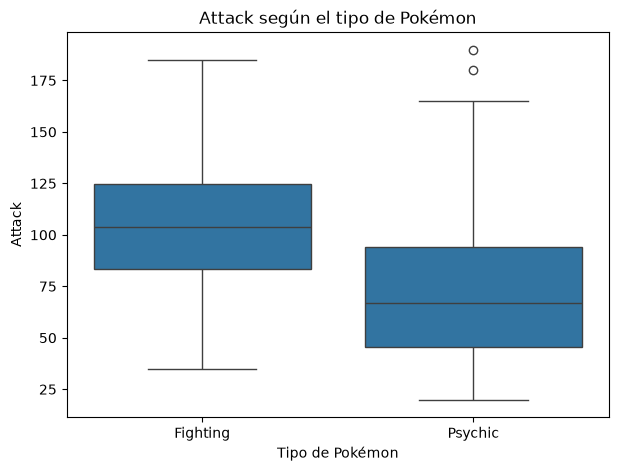

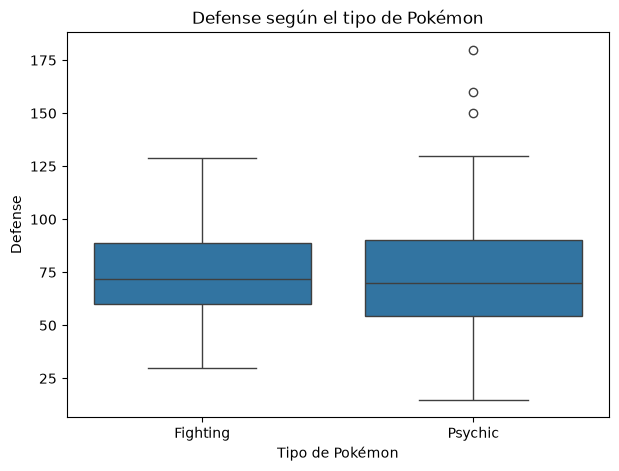

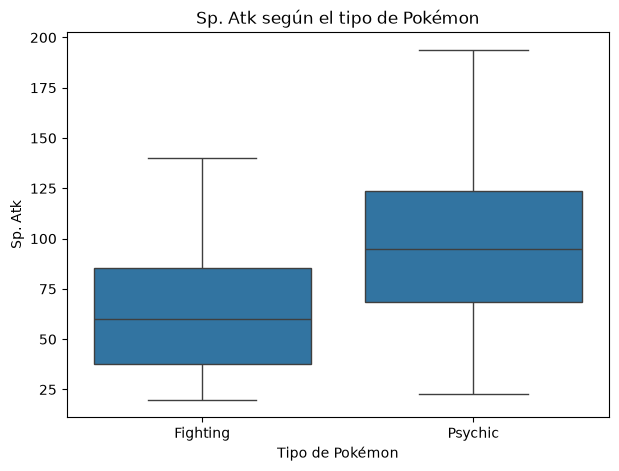

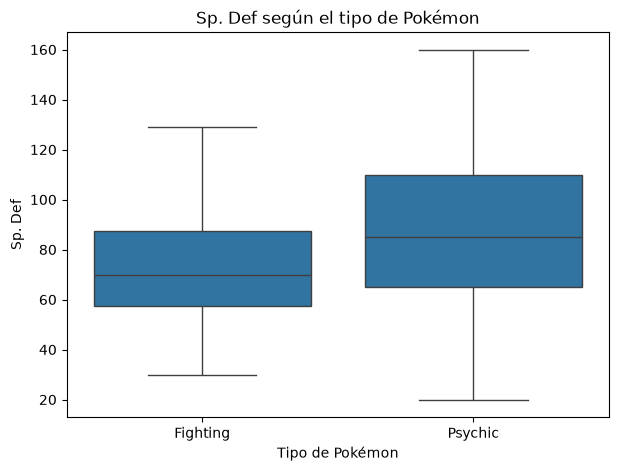

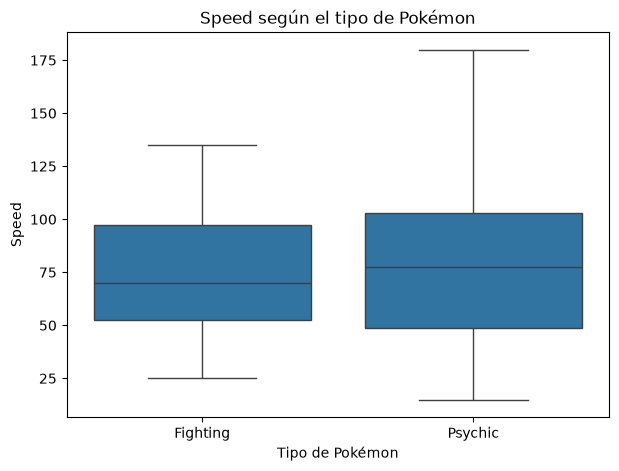

In [23]:
# Distribución de Pokémon por tipo
plt.figure(figsize=(7, 5))

sns.countplot(data=df_filtrado, x='target')

plt.title('Distribución de Pokémon por tipo')
plt.xticks([0, 1], ['Fighting', 'Psychic'])
plt.xlabel('Tipo')
plt.ylabel('Número de Pokémon')
plt.show()


# Comparación de las estadísticas según el tipo
for variable in estadísticas:

    plt.figure(figsize=(7, 5))

    sns.boxplot(data=df_filtrado, x='target', y=variable)
    plt.xticks([0, 1], ['Fighting', 'Psychic'])
    plt.xlabel('Tipo de Pokémon')
    plt.title(f'{variable} según el tipo de Pokémon')
    plt.show()

***
Empezamos a ver cosas interesantes. Si nos fijamos en las gráficas de ataque y ataque especial, vemos que sí que hay una diferecia considerable.

A mayores también vemos que sí que es cierto que tenemos bastantes más pokémon que sean tipo psíquico que tipo lucha (a mayores de que tenemos algún que otro que justamente tiene los dos tipos). 

***

***
Para poder realizar el modelo de clasificación, necesitamos dividir nuestros datos en barios conjuntos. Primero, el conjunto de entrenamiento, que serán los datos a partir de los cuales el modelo intentará sacar una correlación para poder aplicar en los siguientes conjuntos. Este conjunto lo vamos a dividir en dos subconjuntos. Uno para entrenar el modelo y otro para hacer una primera comprobación.


Por último, vamos a escoger otro entrenamiento para ver cómo clasifica un nuevo conjunto.

***

In [25]:
from sklearn.preprocessing import StandardScaler

# Variables predictoras
X = df_filtrado[estadísticas].values

# Variable objetivo
y = df_filtrado['target'].values

# Primera división: entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# División del entrenamiento para obtener validación
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.20, random_state=42, stratify=y_train)

# Escalado de las variables
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


print('\n' + '=' * 50)


print('\nDatos de entrenamiento:', X_train_scaled.shape)
print('Datos de validación:', X_val_scaled.shape)
print('Datos de prueba:', X_test_scaled.shape)

print('\n' + '=' * 50)



Datos de entrenamiento: (87, 6)
Datos de validación: (22, 6)
Datos de prueba: (28, 6)



***

Probamos a variar los tamaños de los conjuntos de entrenamiento, validación y prueba para ver cómo afecta al rendimiento del modelo. Pusimos en el apartado test_size=0.42 igual que como estaba en algunos programas de clase. Sin embargo, nos daba resultados un poco peores, ya que perder elementos en el conjunto de entrenamientos suponía perder precisión.

***


****

### Construcción y entrenamiento de la red neuronal

Para construir nuestra red neuronal nos hemos ido a inspirarnos en el modelo de detección de cancer de mama que tenemos en el aula virtual, ya que de alguna forma también representa una clasificación en sí o no. De esta forma, creamos la siguiente arquitectura:

1. Una red de entrada de 20 neuronas tipo RELU
2. Capa de 20 neuronas tipo RELU
3. Capa de 20 neurones tipo RELU
4. Una última capa de una sola neurona tipo sigmoide

A mayores, escogemos como función de pérdida 'binary_crossentropy', particularmente útil para justamente clasificaciones en dos categorías

Además de todo esto, más adelante usaremos la función Early_stopping para evitar un sobreajuste.

****

In [26]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import SGD

from tensorflow.keras.callbacks import EarlyStopping

# Fijamos la semilla para reproducibilidad
np.random.seed(42) 
tf.random.set_seed(42)

# Creación de la red neuronal
model = keras.Sequential([layers.Dense(20, activation='relu', input_shape=(X_train_scaled.shape[1],)), layers.Dense(20, activation='relu'), layers.Dense(20, activation='relu'), layers.Dense(1, activation='sigmoid')])
#keras.sequential: Crea una red neuronal en la que las capas están organizadas consecutivamente. La información pasa de una capa a la siguiente.
#input_shape=(X_train_scaled.shape[1],): Especifica la forma de los datos de entrada. En este caso, el número de características (columnas) en los datos de entrenamiento escalados. (Indica que cada Pokémon tiene seis características de entrada.)
#layers.Dense(20, activation='relu'): Crea una capa densa (fully connected) con 20 neuronas y la función de activación ReLU (Rectified Linear Unit). Esta capa aprenderá patrones complejos a partir de las características de entrada.
#layer.dense(1, activation='sigmoid'): Crea la capa de salida con una sola neurona y la función de activación sigmoide. Esta capa produce un valor entre 0 y 1, que se interpreta como la probabilidad de que un Pokémon sea de tipo Psíquico (1) o Lucha (0).


# Compilación del modelo
sgd = SGD(learning_rate=0.01)

model.compile(optimizer=sgd, loss='binary_crossentropy', metrics=['accuracy'])
#SGD: algoritmo que modifica los pesos de la red para mejorar sus predicciones.
#Learning rate = 0.01: determina el tamaño de los cambios que realiza el algoritmo durante el aprendizaje.
#Binary crossentropy: función que mide el error de las predicciones en un problema de dos categorías.
#Accuracy: mide el porcentaje de predicciones correctas.

# Resumen de la arquitectura
model.summary()

c:\Users\david\anaconda3\envs\tensorflow_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 20)             │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,001 (3.91 KB)

 Trainable params: 1,001 (3.91 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Early Stopping para evitar sobreajuste
early_stop = EarlyStopping(monitor='val_loss', patience=40, restore_best_weights=True)

# Entrenamiento
print("Entrenando la red neuronal...")

history = model.fit(X_train_scaled, y_train, epochs=500, batch_size=10, validation_data=(X_val_scaled, y_val), callbacks=[early_stop], verbose=1)
#X_train_scaled: características de los Pokémon utilizados para entrenar.
#y_train: clasificación correcta de esos Pokémon.
#epochs=500: número máximo de veces que el modelo puede recorrer los datos de entrenamiento.
#batch_size=10: procesa los datos en grupos de diez ejemplos antes de actualizar los pesos.
#validation_data: proporciona los datos de validación para controlar el aprendizaje.

print("\n¡Entrenamiento completado!")

print("Número de épocas ejecutadas:", len(history.history['loss']))

Entrenando la red neuronal...
Epoch 1/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.2299 - loss: 0.8312 - val_accuracy: 0.1364 - val_loss: 0.8310
Epoch 2/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2299 - loss: 0.7913 - val_accuracy: 0.1818 - val_loss: 0.7965
Epoch 3/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2989 - loss: 0.7628 - val_accuracy: 0.2273 - val_loss: 0.7712
Epoch 4/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4713 - loss: 0.7419 - val_accuracy: 0.3182 - val_loss: 0.7517
Epoch 5/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4943 - loss: 0.7260 - val_accuracy: 0.5000 - val_loss: 0.7359
Epoch 6/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5977 - loss: 0.7133 - val_accuracy: 0.5909 - val_loss: 0.7225
Epoch 7/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6207 - loss: 0.7027 - val_accuracy: 0.6364 - val_loss: 0.7112
Epoch 8/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6207 - loss: 0.6940 - val_accu

In [17]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

# Predicciones de la red neuronal
y_prob = model.predict(X_test_scaled)

# Convertimos probabilidades en clases: de esta forma las probabilidades mayores o iguales a 0.7 se consideran como clase 1 (Psíquico) y las menores como clase 0 (Lucha). Esto permite ajustar la sensibilidad del modelo según las necesidades del análisis.
y_hat_test = (y_prob >= 0.7).astype(int).ravel()



# Accuracy
print("Red Neuronal - Accuracy:", accuracy_score(y_test, y_hat_test))

# Informe de clasificación
print("\nInforme de clasificación:")

print(classification_report(y_test, y_hat_test, target_names=['Psychic', 'Fighting'], zero_division=0))

# Matriz de confusión
print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_hat_test))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step
Red Neuronal - Accuracy: 0.8571428571428571

Informe de clasificación:
              precision    recall  f1-score   support

     Psychic       0.80      0.80      0.80        10
    Fighting       0.89      0.89      0.89        18

    accuracy                           0.86        28
   macro avg       0.84      0.84      0.84        28
weighted avg       0.86      0.86      0.86        28


Matriz de confusión:
[[ 8  2]
 [ 2 16]]


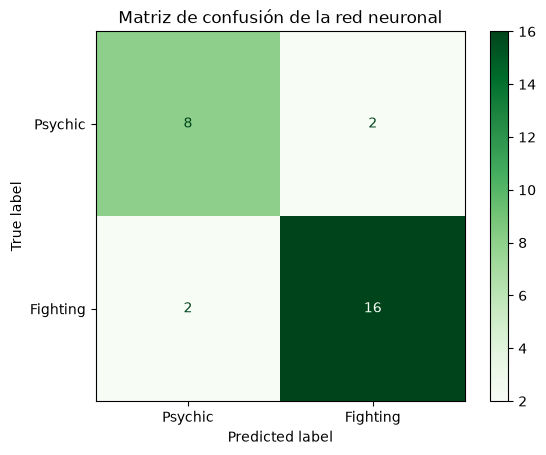

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_hat_test)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Psychic', 'Fighting'])

disp.plot(cmap='Greens')

plt.title('Matriz de confusión de la red neuronal')
plt.show()

***

Con el valor de accuracy de la red de 0,85 y la matriz de confusión podemos ver que efectivamente, se cumple que los pokemon psíquico y los lucha tienden a tener sus estadísticas bastante determinadas solo por el tipo pokemon del que estemos hablando.

Lo podemos ver también en la matriz de confusión, donde vemos que el modelo solo falla en 4 casos del conjunto de test.

***


***


Vamos por curiosidad a representar las curvas de cómo crecen la precisión y disminuye la pérdida a medida que usamos las épocas. Si efectivamente no hemos sobreentredado el modelo, entonces la curva de pérdida. Si efectivamente no hemos sobreentrenado el modelo, la curva de la pérdida de valoración debería ser siempre decreciente, como efectivamente es.


***

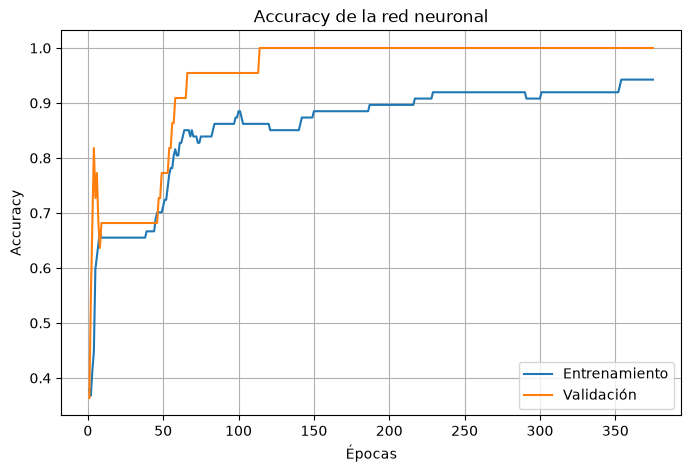

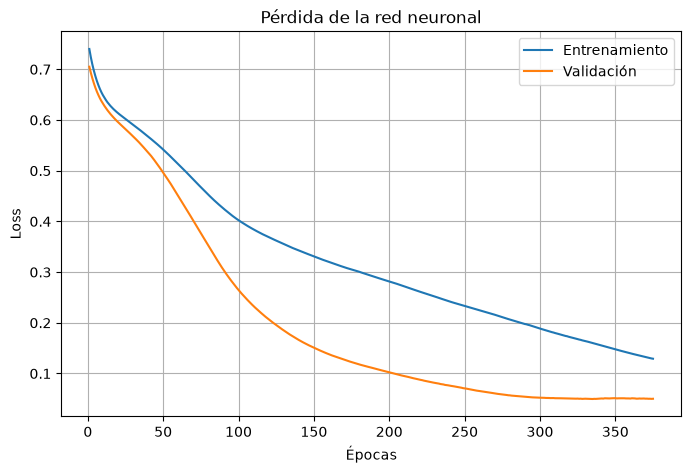

In [ ]:
# Extraemos los datos del historial


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)


# Gráfica de Accuracy
plt.figure(figsize=(8, 5))

plt.plot(epochs, acc, label='Entrenamiento')

plt.plot(epochs, val_acc, label='Validación')

plt.title('Accuracy de la red neuronal')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.show()


# Gráfica de Loss
plt.figure(figsize=(8, 5))

plt.plot(epochs, loss, label='Entrenamiento')

plt.plot(epochs, val_loss, label='Validación')

plt.title('Pérdida de la red neuronal')
plt.xlabel('Épocas')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.show()